In [1]:
# CPU/GPU selection: run this cell before importing jax or the estimator elsewhere.
# After changing MODE, restart the kernel and run all cells from the top.
# GPU mode requires CUDA-enabled JAX in a Linux/WSL2 kernel.
import os

MODE = "cpu"  # "cpu" or "gpu"
if MODE not in {"cpu", "gpu"}:
    raise ValueError('MODE must be "cpu" or "gpu".')

# Keep CPU available in GPU mode for operations explicitly placed on CPU.
os.environ["JAX_PLATFORMS"] = "cpu" if MODE == "cpu" else "cuda,cpu"

import jax

backend = jax.default_backend()
expected_backends = {"cpu"} if MODE == "cpu" else {"gpu", "cuda"}
if backend not in expected_backends:
    raise RuntimeError(
        f"JAX backend is {backend!r}, expected one of {sorted(expected_backends)} "
        f"for MODE={MODE!r}; restart the kernel and run all cells."
    )
print("Backend:", backend)
print("Devices:", jax.devices())


Backend: cpu
Devices: [CpuDevice(id=0)]


# Demo 1: CSP factor model — block loadings (`GibbsCSP`)

**Model**: $x_i = B\eta_i + \varepsilon_i$, $\eta_i \sim \mathcal N_H(0, I)$,
$\varepsilon_i \sim \mathcal N_p(0, \Omega)$, $\Omega$ diagonal, with the
**cumulative shrinkage process** prior on the column variances $\theta_h$
(Legramanti, Durante & Dunson 2020, *Biometrika*, eq. 6): a spike-and-slab
mixture whose spike mass $\pi_h$ grows with the column index via
stick-breaking.

**Data design** (the block design used by the current CSP analysis,
$n = 100 \ll p = 1956$, $r = 5$ true factors):

- column $k$ of the true loading matrix $B_0$ equals 1 on 500 consecutive
  rows starting at row $364(k-1)$ — five partially overlapping blocks;
- $\Omega_0 = I_p$ (homoscedastic noise),
  $\Sigma_0 = B_0 B_0^\top + \Omega_0$.

**Inference**: the `GibbsCSP` estimator (sklearn-style wrapper of the
paper's Algorithm 1 Gibbs sampler) with a fixed truncation $H = 50$.
The notebook keeps the selected CSP data and sampler settings:
`DATA_SEED = 1`, `SAMPLER_SEED = 2025`, 20,000 sweeps, 10,000 burn-in,
thin = 10, $\alpha = 5$, $a_\theta = b_\theta = 2$,
$\theta_\infty = 0.05$, and $(a_\sigma, b_\sigma) = (1, 0.3)$.

**What is shown**: automatic factor-dimension selection via the posterior
of $H^*$; noise, covariance and factor-subspace recovery; posterior
uncertainty of $\Sigma$; MCMC mixing diagnostics (ESS via ArviZ); and,
in the final section, one RSP alignment with on-demand factor scores and
a before/after audit of the CSP prior, factor counts and column norms.


In [2]:
import hashlib
import sys
import time
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

# The notebook lives in CSP_BFM/demos/: walk up to the directory containing
# the CSP_JAX package and put it on sys.path.
root = next(d for d in (Path.cwd(), *Path.cwd().parents) if (d / "CSP_JAX").is_dir())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import jax
from CSP_JAX import GibbsCSP

# ---------------------------------------------------------------------------
# Consistent, publication-friendly plotting style shared by the demos.
# ---------------------------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#5b6472",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6eaf0",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlepad": 8,
    "axes.labelsize": 10,
    "axes.labelcolor": "#30363f",
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "xtick.color": "#30363f",
    "ytick.color": "#30363f",
    "legend.fontsize": 9,
    "legend.frameon": False,
    "font.family": "DejaVu Sans",
})
C_GS, C_TRUE, C_SHRUNK, C_FLOOR = "#2f6fd0", "#b03a2e", "#c9d3df", "#7a5c00"

print("package root:", root, "| jax backend:", jax.default_backend())


package root: C:\Users\kexio\Documents\GitHub\CSP_BFM | jax backend: cpu


## 1. Simulate the data (fixed block design and data seed)

The design is fixed: $n = 100$, $p = 1956$, five true blocks of length 500
starting at rows $364(k-1)$. `DATA_SEED = 1` reproduces the selected data;
`SAMPLER_SEED = 2025` is used later for the Gibbs chain and for the
on-demand factor scores.

The estimator centers the columns internally (`center=True` by default),
so `X` is passed uncentered — unlike the raw `GS_CSP` driver, which assumes
a zero-mean input.


In [3]:
DATA_SEED = 1
SAMPLER_SEED = 2025
np.random.seed(DATA_SEED)
print(f"Seeds: data={DATA_SEED}, Gibbs/scores={SAMPLER_SEED}")

P, K0, N = 1956, 5, 100
B_0 = np.zeros((P, K0))
for j in range(K0):
    B_0[364 * j: 364 * j + 500, j] = 1.0
cov_0 = B_0 @ B_0.T + np.eye(P)                # Sigma_0 = B_0 B_0' + I
X = np.random.multivariate_normal(np.zeros(P), cov_0, N)

Sig_true = cov_0
s2_true = np.diag(cov_0) - (B_0 ** 2).sum(1)   # = 1 for every variable
print(f"X: {X.shape}  (n = {N}, p = {P}, true factors r = {K0})")
print("true block column norms:", np.round(np.linalg.norm(B_0, axis=0), 2))


Seeds: data=1, Gibbs/scores=2025


X: (100, 1956)  (n = 100, p = 1956, true factors r = 5)
true block column norms: [22.36 22.36 22.36 22.36 22.36]


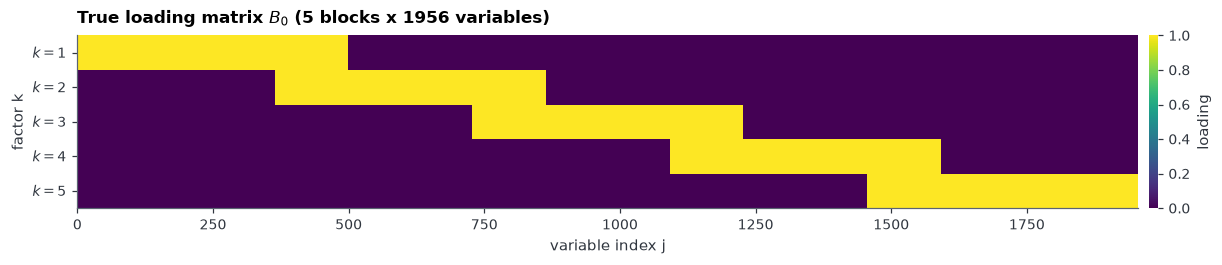

In [4]:
fig, ax = plt.subplots(figsize=(11, 2.3), constrained_layout=True)
im = ax.imshow(B_0.T, aspect="auto", interpolation="nearest", cmap="viridis")
ax.set_title(f"True loading matrix $B_0$ ({K0} blocks x {P} variables)", loc="left")
ax.set_xlabel("variable index j")
ax.set_ylabel("factor k")
ax.set_yticks(np.arange(K0))
ax.set_yticklabels([f"$k={k + 1}$" for k in range(K0)])
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.01)
cb.set_label("loading")
cb.outline.set_visible(False)
plt.show()


## 2. Fit the CSP Gibbs sampler

- Truncation level **H = 50**, deliberately larger than the true $r = 5$:
  at most $H-1 = 49$ columns can be active because the $H$th column is
  spiked by construction. Relative to the five true blocks, this leaves
  $H-r = 45$ excess columns; Section 3 reads the active count from the
  posterior of $H^*$, and Section 6a explains how the positive spike
  variance gives those columns aggregate slack.
- Hyperparameters follow Section 4 of the paper: `alpha = 5` (the prior
  expected number of active factors in the infinite process is
  $E(H^*) = \alpha$), `a_theta = b_theta = 2`, `theta_inf = 0.05`,
  `(a_sigma, b_sigma) = (1, 0.3)`. `a_theta > 1` satisfies the condition
  of the paper's Theorem 2.
- 20,000 sweeps, 10,000 burn-in, keep every 10th → $S = 1000$ retained
  draws. The stored loading array is $S \times p \times H$ float32
  (about 373 MiB / 391 MB at these settings), which is why thinning
  matters.
- `seed = SAMPLER_SEED` seeds one explicit `jax.random.PRNGKey` (no global
  RNG state); the used seed is stored as `seed_`.
- The first call includes one-time XLA ahead-of-time compilation
  (seconds, **not** counted in `runtime_sec_`).
- The truncation is intentionally over-sized here. Its cost is the
  larger per-sweep and storage footprint; its statistical effect is
  discussed with the spike floor in Section 3 and audited in Section 6a.


In [5]:
H = 50
ALPHA = 5.0
A_THETA = 2.0
B_THETA = 2.0
THETA_INF = 0.05
A_SIGMA = 1.0
B_SIGMA = 0.3
N_ITER = 20000
BURN_IN = 10000
THIN = 10

t0 = time.perf_counter()
gs = GibbsCSP(
    H=H, alpha=ALPHA, a_theta=A_THETA, b_theta=B_THETA,
    theta_inf=THETA_INF, a_sigma=A_SIGMA, b_sigma=B_SIGMA,
    n_iter=N_ITER, burn_in=BURN_IN, thin=THIN,
    seed=SAMPLER_SEED, verbose=False,
).fit(X)
wall = time.perf_counter() - t0
S = gs.B_samples_.shape[0]
assert S == (N_ITER - BURN_IN) // THIN
assert gs.seed_ == SAMPLER_SEED

print("-" * 78)
print(
    f"GibbsCSP | {S} kept draws (every {gs.thin}th of "
    f"{gs.n_iter - gs.burn_in} post-burn-in sweeps) | "
    f"scan {gs.runtime_sec_:.1f}s "
    f"({1e3 * gs.runtime_sec_ / gs.n_iter:.1f} ms/sweep) | "
    f"wall {wall:.1f}s (includes one-time XLA compilation)"
)
print(f"stored B draws: {gs.B_samples_.nbytes / 2**20:.1f} MiB "
      f"(S x p x H = {S} x {P} x {H}, float32)")
print("-" * 78)


------------------------------------------------------------------------------
GibbsCSP | 1000 kept draws (every 10th of 10000 post-burn-in sweeps) | scan 563.9s (28.2 ms/sweep) | wall 572.0s (includes one-time XLA compilation)
stored B draws: 373.1 MiB (S x p x H = 1000 x 1956 x 50, float32)
------------------------------------------------------------------------------


## 3. Automatic selection of the factor dimension via $H^*$

The CSP prior's headline feature is that the active-factor count
$H^* = \sum_h \mathbb 1(z_h > h)$ is sampled every sweep, so its posterior
estimates the model dimension directly. `n_factors()` defaults to the
posterior median of $H^*$; `method="credible"` is an auxiliary entry-wise
marginal credible-interval rule, not the CSP dimension rule. $H^*$ is
computed in the prior's coordinate system, before any RSP alignment.

The third panel shows the posterior mean of the **per-draw** column L2
norm,
$\frac{1}{S}\sum_s \|B_{\cdot h}^{(s)}\|_2$ — not the norm of the
posterior-mean column $\|\frac{1}{S}\sum_s B_{\cdot h}^{(s)}\|_2$. Columns
beyond the true dimension shrink toward the spike. A spiked column has
entries approximately $N(0, \theta_\infty)$, so its typical L2 norm is
$\sqrt{p\,\theta_\infty} \approx 9.9$; the dotted line is that scale
reference, not a selection threshold.

At $H = 50$ with $r = 5$, there are $H-r = 45$ excess columns before
considering which true block is active. If the $H^*$ posterior selects
four factors (the current analysis), there are 46 inactive columns
($H - 4 = 46$): those 45 plus the one true block absorbed by the spike
(the 50th column is one of those spiked columns by construction).
The positive
$\theta_\infty$ is not merely a numerical floor: every spiked column still
has marginal variance $\theta_\infty$ at every entry, so the spiked
columns collectively provide aggregate slack that can explain a weak
block without assigning it an active factor. This statistical slack is
separate from the computational cost of over-truncation: the 45 excess
columns enlarge each sweep and the stored loading array whether or not
they are active. Section 6a audits the counts and all-column norms
without applying a max-abs threshold.


H* posterior: mean = 4.00, median = 4, 95% CI = (4, 4)  (true r = 5, 1000 draws)
n_factors() [H* median]  = 4
n_factors('credible')    = 4


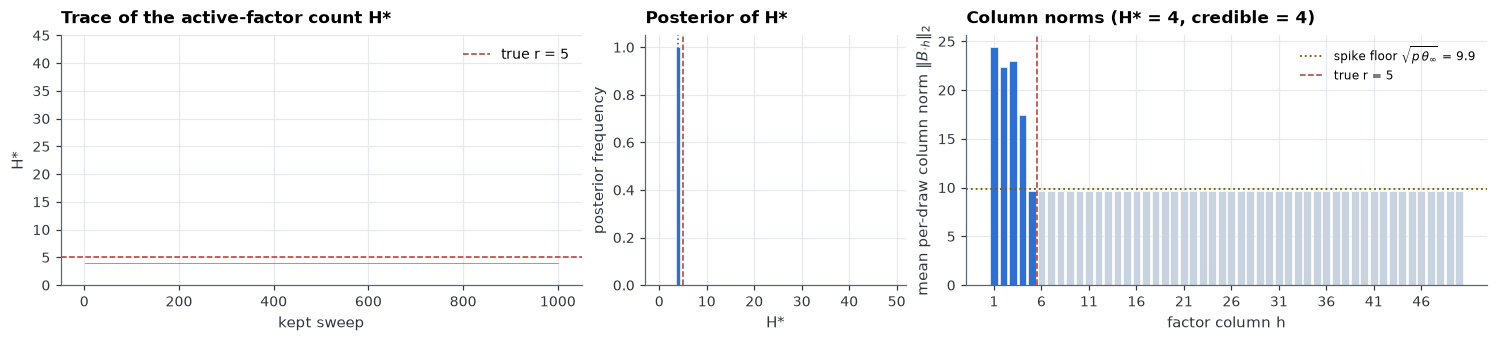

per-draw L2 column norms, averaged over draws: [24.393 22.397 22.988 17.443  9.688  9.683  9.695  9.671  9.693  9.69
  9.686  9.683  9.689  9.68   9.687  9.682  9.68   9.68   9.671  9.687
  9.686  9.668  9.684  9.687  9.679  9.675  9.677  9.683  9.671  9.681
  9.673  9.692  9.676  9.683  9.678  9.683  9.683  9.679  9.691  9.68
  9.678  9.689  9.677  9.685  9.662  9.688  9.677  9.685  9.691  9.681]


In [6]:
summ = gs.h_star_summary()
n_hstar = gs.n_factors()
n_credible = gs.n_factors(method="credible")
print(
    f"H* posterior: mean = {summ['mean']:.2f}, median = {summ['median']:.0f}, "
    f"95% CI = ({summ['ci'][0]:.0f}, {summ['ci'][1]:.0f})  "
    f"(true r = {K0}, {summ['n_draws']} draws)"
)
print(f"n_factors() [H* median]  = {n_hstar}")
print(f"n_factors('credible')    = {n_credible}")

hs = gs.H_star_samples_
assert n_hstar == int(np.median(hs))
colnorm = np.linalg.norm(gs.B_samples_, axis=1).mean(0)
spike_floor = np.sqrt(P * gs.theta_inf)

fig, axes = plt.subplots(
    1, 3, figsize=(13.5, 3.0), constrained_layout=True,
    gridspec_kw={"width_ratios": [1.6, 0.8, 1.6]},
)
axes[0].plot(np.arange(1, S + 1), hs, color=C_GS, lw=0.6, alpha=0.7)
axes[0].axhline(K0, color=C_TRUE, ls="--", lw=1.0, label=f"true r = {K0}")
axes[0].set_xlabel("kept sweep")
axes[0].set_ylabel("H*")
axes[0].set_yticks(np.arange(0, H, max(1, H // 10)))
axes[0].set_title("Trace of the active-factor count H*", loc="left")
axes[0].legend(loc="upper right")

counts = np.bincount(hs, minlength=H)[:H]
axes[1].bar(np.arange(H), counts / S, width=0.82, color=C_GS,
            edgecolor="white", linewidth=0.4)
axes[1].axvline(K0, color=C_TRUE, ls="--", lw=1.0)
axes[1].axvline(n_hstar, color=C_GS, ls=":", lw=1.1)
axes[1].set_xlabel("H*")
axes[1].set_ylabel("posterior frequency")
axes[1].set_title("Posterior of H*", loc="left")

xs = np.arange(1, H + 1)
axes[2].bar(
    xs, colnorm, width=0.82,
    color=np.where(xs <= K0, C_GS, C_SHRUNK),
    edgecolor="white", linewidth=0.4,
)
axes[2].axhline(
    spike_floor, color=C_FLOOR, ls=":", lw=1.2,
    label=rf"spike floor $\sqrt{{p\,\theta_\infty}}$ = {spike_floor:.1f}",
)
axes[2].axvline(K0 + 0.5, color=C_TRUE, ls="--", lw=1.0,
                label=f"true r = {K0}")
axes[2].set_xlabel("factor column h")
axes[2].set_ylabel(r"mean per-draw column norm $\|B_{\cdot h}\|_2$")
axes[2].set_title(f"Column norms (H* = {n_hstar}, credible = {n_credible})",
                  loc="left")
axes[2].set_xticks(xs[:: max(1, H // 10)])
axes[2].legend(loc="upper right", fontsize=8)
plt.show()

print("per-draw L2 column norms, averaged over draws:",
      np.round(colnorm, 3))


## 4. Recovery of $\sigma^2$, the covariance matrix, and the factor subspace (pre-RSP)

Every recovery and uncertainty diagnostic in Sections 4-5 uses the raw
draws, before the single RSP call in Section 6. The plug-in is constructed
explicitly from raw draw means,
\[
\bar B = \frac1S\sum_s B^{(s)},\qquad
\bar\sigma^2 = \frac1S\sum_s \sigma^{2,(s)},\qquad
\widehat\Sigma_{\text{plug}} = \bar B\bar B^\top
+ \operatorname{diag}(\bar\sigma^2),
\]
rather than from `gs.Sigma_`, whose `B_hat_` changes after alignment.

The table reports both errors
\[
\text{Frobenius error}=\|\widehat\Sigma-\Sigma_0\|_F,
\qquad
\text{relative Frobenius error}
=\frac{\|\widehat\Sigma-\Sigma_0\|_F}{\|\Sigma_0\|_F},
\]
for the raw plug-in and for the Monte Carlo posterior mean
$\Sigma_{mc} = \frac1S\sum_s (B^{(s)}B^{(s)\top}
+ \operatorname{diag}(\sigma^{2,(s)}))$ (`gs.Sigma_mc_`, aliased as
`gs.Sigma_mean_`). The absolute error keeps the covariance scale; the
relative error normalizes by the same true-covariance norm. Principal-angle
cosines compare the top-$r$ raw loading columns with the true factor space
(1 = aligned).


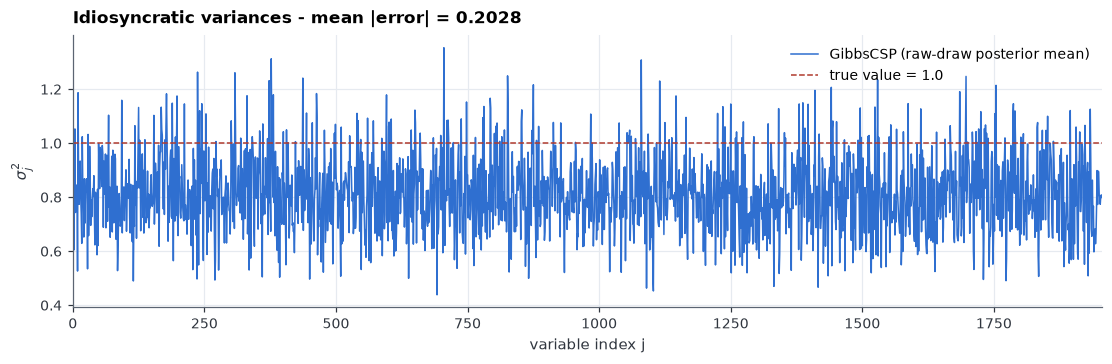

In [7]:
sigma2_raw_mean = gs.sigma2_samples_.mean(axis=0)
np.testing.assert_allclose(sigma2_raw_mean, gs.sigma2_hat_, rtol=1e-6, atol=1e-6)
err_sigma2 = np.abs(sigma2_raw_mean - s2_true).mean()

fig, ax = plt.subplots(figsize=(10, 3.2), constrained_layout=True)
ax.plot(sigma2_raw_mean, color=C_GS, lw=1.0,
        label="GibbsCSP (raw-draw posterior mean)")
ax.axhline(float(s2_true[0]), color=C_TRUE, ls="--", lw=1.0,
           label=f"true value = {s2_true[0]:.1f}")
ax.set_xlabel("variable index j")
ax.set_ylabel(r"$\sigma_j^2$")
ax.set_title(f"Idiosyncratic variances - mean |error| = {err_sigma2:.4f}",
             loc="left")
ax.set_xlim(0, P - 1)
ax.legend(loc="upper right")
plt.show()


Covariance estimation errors before RSP alignment
||Sigma_true||_F = 1185.294900
Estimate                              Frobenius error     Relative Frobenius
raw plug-in Sigma                          546.391696               0.460975
Sigma_mc_ (posterior mean)                 515.439937               0.434862
principal-angle cosines (raw draws): [0.985  0.9829 0.98   0.9693 0.6944]


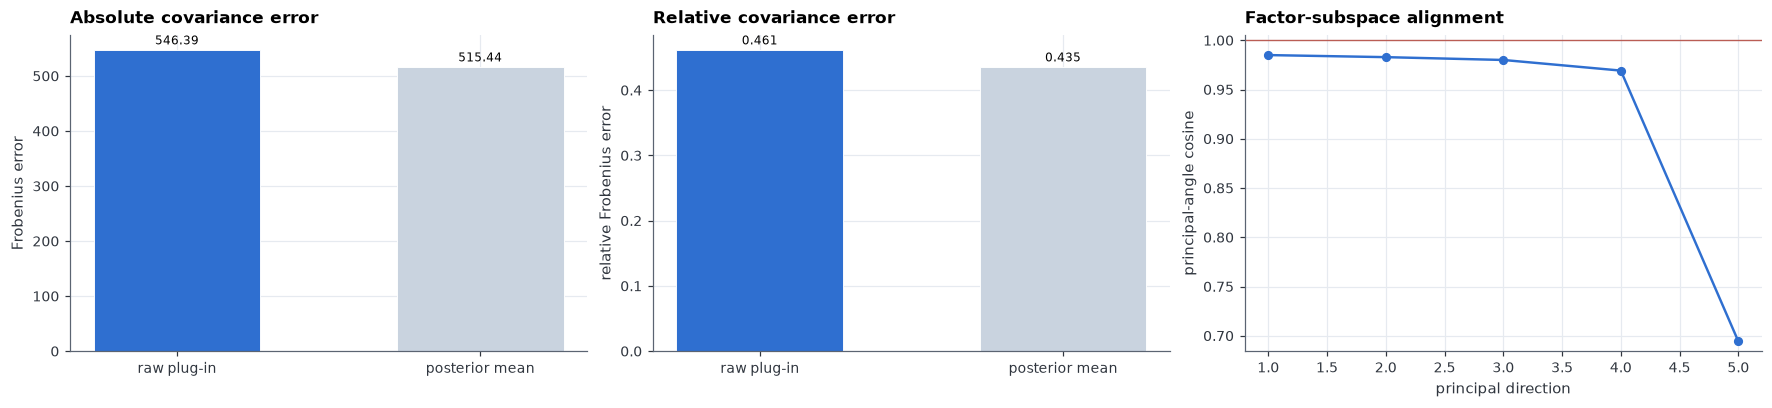

In [8]:
# Use explicit raw-draw means, not gs.Sigma_: gs.B_hat_/Sigma_ change after
# RSP alignment, so this cell remains valid if rerun later.
B_raw_mean = gs.B_samples_.mean(axis=0)
sigma2_raw_mean = gs.sigma2_samples_.mean(axis=0)
Sigma_plugin_raw = B_raw_mean @ B_raw_mean.T + np.diag(sigma2_raw_mean)
Sigma_mc = gs.Sigma_mc_                    # MC mean; alias gs.Sigma_mean_

norm_Sig_true = float(np.linalg.norm(Sig_true, ord="fro"))


def froerr(Sig):
    return float(np.linalg.norm(Sig - Sig_true, ord="fro"))


def relerr(Sig):
    return froerr(Sig) / norm_Sig_true


fro_plug, fro_mc = froerr(Sigma_plugin_raw), froerr(Sigma_mc)
rel_plug, rel_mc = relerr(Sigma_plugin_raw), relerr(Sigma_mc)
print("Covariance estimation errors before RSP alignment")
print(f"||Sigma_true||_F = {norm_Sig_true:.6f}")
print(f"{'Estimate':<32} {'Frobenius error':>20} {'Relative Frobenius':>22}")
for label, absolute, relative in (
    ("raw plug-in Sigma", fro_plug, rel_plug),
    ("Sigma_mc_ (posterior mean)", fro_mc, rel_mc),
):
    print(f"{label:<32} {absolute:20.6f} {relative:22.6f}")

# Subspace alignment on the raw draws: top-r columns vs the true factor space.
U_true = np.linalg.qr(B_0)[0][:, :K0]
U_raw = np.linalg.qr(B_raw_mean)[0][:, :K0]
cosines = np.linalg.svd(U_raw.T @ U_true, compute_uv=False)
print("principal-angle cosines (raw draws):", np.round(cosines, 4))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), constrained_layout=True)
x = np.arange(2)
bars_abs = axes[0].bar(x, [fro_plug, fro_mc], 0.55,
                       color=[C_GS, C_SHRUNK], edgecolor="white",
                       linewidth=0.6)
axes[0].set_xticks(x)
axes[0].set_xticklabels(["raw plug-in", "posterior mean"])
axes[0].set_ylabel("Frobenius error")
axes[0].set_title("Absolute covariance error", loc="left")
axes[0].bar_label(bars_abs, fmt="%.2f", padding=2, fontsize=8)

bars_rel = axes[1].bar(x, [rel_plug, rel_mc], 0.55,
                       color=[C_GS, C_SHRUNK], edgecolor="white",
                       linewidth=0.6)
axes[1].set_xticks(x)
axes[1].set_xticklabels(["raw plug-in", "posterior mean"])
axes[1].set_ylabel("relative Frobenius error")
axes[1].set_title("Relative covariance error", loc="left")
axes[1].bar_label(bars_rel, fmt="%.3f", padding=2, fontsize=8)

axes[2].plot(np.arange(1, K0 + 1), cosines, "o-", ms=5, lw=1.6, color=C_GS)
axes[2].axhline(1.0, color=C_TRUE, lw=0.9, alpha=0.8)
axes[2].set_ylim(min(cosines) - 0.01, 1.005)
axes[2].set_xlabel("principal direction")
axes[2].set_ylabel("principal-angle cosine")
axes[2].set_title("Factor-subspace alignment", loc="left")
plt.show()


## 4b. Covariance heatmaps: truth vs raw-draw estimates (pre-RSP)

Heatmaps of (a) the true covariance $\Sigma_0$, (b) the Monte Carlo
posterior-mean covariance $E[\Sigma\mid X]$ (`gs.Sigma_mc_`), and (c) the
raw plug-in $\bar B\bar B^\top + \operatorname{diag}(\bar\sigma^2)$ built
from the raw draw means. All panels share one color scale. Panel (c) is
the pre-RSP plug-in; the aligned plug-in `gs.Sigma_` can differ and is not
used here.


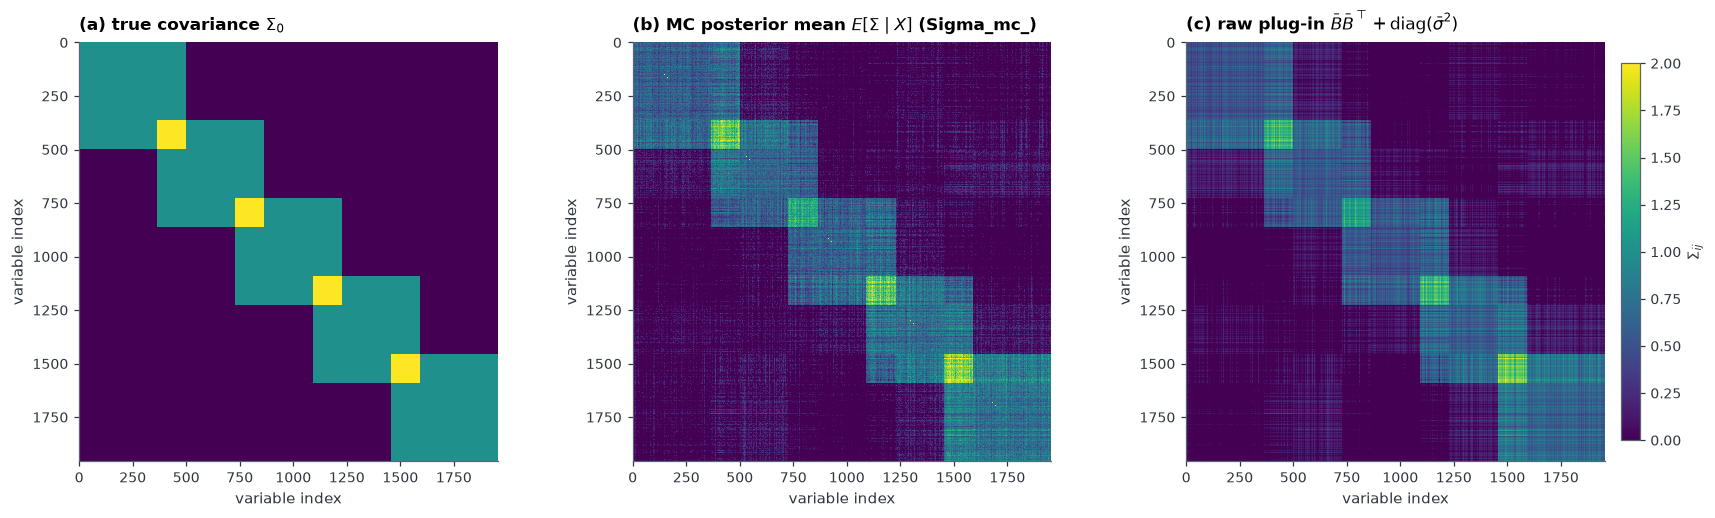

In [9]:
panels = (
    (r"(a) true covariance $\Sigma_0$", Sig_true),
    (r"(b) MC posterior mean $E[\Sigma\mid X]$ (Sigma_mc_)", Sigma_mc),
    (r"(c) raw plug-in $\bar B\bar B^\top + \mathrm{diag}(\bar\sigma^2)$",
     Sigma_plugin_raw),
)
vmax = float(np.percentile(
    np.concatenate([np.asarray(M, dtype=float).ravel() for _, M in panels]),
    99.5,
))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), constrained_layout=True)
for ax, (title, M) in zip(axes, panels):
    im = ax.imshow(M, cmap="viridis", vmin=0.0, vmax=vmax,
                   interpolation="nearest")
    ax.set_title(title, loc="left")
    ax.set_xlabel("variable index")
    ax.set_ylabel("variable index")
    ax.grid(False)
cb = fig.colorbar(im, ax=axes, pad=0.01, shrink=0.9)
cb.set_label(r"$\Sigma_{ij}$")
plt.show()


## 4c. Posterior uncertainty of $\Sigma$ (raw draws)

`Sigma_diag_var_` is the cheap entrywise variance of the diagonal (all
draws, $O(SpH)$); `cov_Sigma(pairs)` gives arbitrary entry-pair
covariances at $O(SH)$ per pair. The full `Sigma_var_` matrix costs
$O(Sp^2H)$ and is budget-guarded (deterministic equidistant subsample plus
a warning); `posterior_sigma_var(max_draws=None)` forces it. These Monte
Carlo moments are computed from the raw draws and are invariant to the RSP
alignment in Section 6; the full matrix is not needed for this demo.


posterior SD of Sigma_jj: mean = 0.557 (all 1000 draws)
Var(Sigma_01) = 1.575e-01, Cov(Sigma_01, Sigma_23) = -2.819e-03


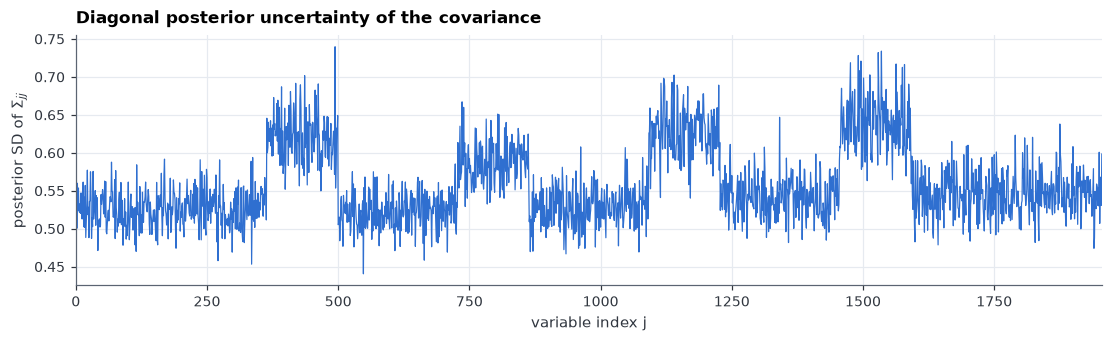

In [10]:
gs_sd_diag = np.sqrt(gs.Sigma_diag_var_)
pair_var = float(gs.cov_Sigma([((0, 1), (0, 1))])[0])
pair_cov = float(gs.cov_Sigma([((0, 1), (2, 3))])[0])
print(f"posterior SD of Sigma_jj: mean = {gs_sd_diag.mean():.3f} "
      f"(all {S} draws)")
print(f"Var(Sigma_01) = {pair_var:.3e}, "
      f"Cov(Sigma_01, Sigma_23) = {pair_cov:.3e}")

fig, ax = plt.subplots(figsize=(10, 3.0), constrained_layout=True)
ax.plot(gs_sd_diag, color=C_GS, lw=0.8)
ax.set_xlabel("variable index j")
ax.set_ylabel(r"posterior SD of $\Sigma_{jj}$")
ax.set_title("Diagonal posterior uncertainty of the covariance", loc="left")
ax.set_xlim(0, P - 1)
plt.show()


## 5. MCMC mixing diagnostics: effective sample size (via ArviZ)

Per-entry bulk ESS of the loading draws, the noise variances and the
$H^*$ chain. ArviZ is an optional dependency: install it from the
`CSP_BFM` directory with `python -m pip install -e ".[ess]"` if needed.
The ~400 rule of thumb applies to the entries that carry signal; shrunk
spike entries are pinned near zero and mix slowly by design — harmless.
The $H^*$ chain is a small integer chain. When it is constant (a common
outcome when the dimension posterior concentrates), ArviZ's bulk ESS is
reported as the number of draws by the package convention; that is not
evidence of poor mixing.


B        min=     1.4  median=   280.7  mean=   275.0  max=   824.7  (draws=1000)
sigma2   min=   448.5  median=   937.8  mean=   928.4  max=  1231.2  (draws=1000)
H_star   min=  1000.0  median=  1000.0  mean=  1000.0  max=  1000.0  (draws=1000)


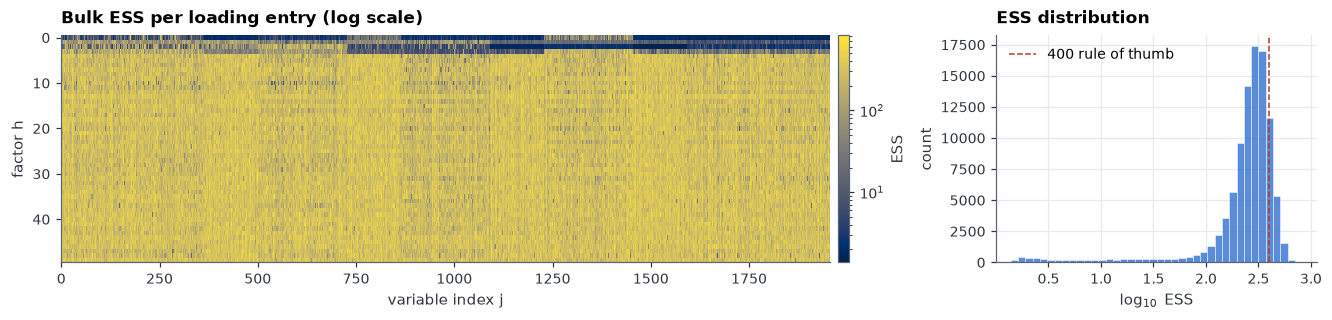

In [11]:
from matplotlib.colors import LogNorm

try:
    summary = gs.ess_summary()
except ImportError as exc:
    summary = None
    print("ESS diagnostics skipped:", exc)
    print('Install the optional dependency with: '
          'python -m pip install -e ".[ess]"')

if summary is not None:
    for k, v in summary.items():
        print(f"{k:8s} min={v['min']:8.1f}  median={v['median']:8.1f}  "
              f"mean={v['mean']:8.1f}  max={v['max']:8.1f}  "
              f"(draws={v['n_draws']})")

    ess_B = gs.ess()["B"]
    vals = ess_B.ravel()
    vals = vals[np.isfinite(vals) & (vals > 0)]
    vmin = max(1.0, float(np.min(vals)))
    vmax = max(vmin * 1.01, float(np.max(vals)))
    fig, axes = plt.subplots(1, 2, figsize=(12, 2.8), constrained_layout=True,
                             gridspec_kw={"width_ratios": [2.4, 1.0]})
    im = axes[0].imshow(ess_B.T, aspect="auto", interpolation="nearest",
                        norm=LogNorm(vmin=vmin, vmax=vmax), cmap="cividis")
    axes[0].set_title("Bulk ESS per loading entry (log scale)", loc="left")
    axes[0].set_xlabel("variable index j")
    axes[0].set_ylabel("factor h")
    axes[0].grid(False)
    cb = fig.colorbar(im, ax=axes[0], pad=0.01)
    cb.set_label("ESS")
    axes[1].hist(np.log10(vals), bins=40, color=C_GS, alpha=0.8,
                 edgecolor="white", linewidth=0.4)
    axes[1].axvline(np.log10(400.0), color=C_TRUE, ls="--", lw=1.0,
                    label="400 rule of thumb")
    axes[1].set_title("ESS distribution", loc="left")
    axes[1].set_xlabel(r"$\log_{10}$ ESS")
    axes[1].set_ylabel("count")
    axes[1].legend(loc="upper left")
    plt.show()


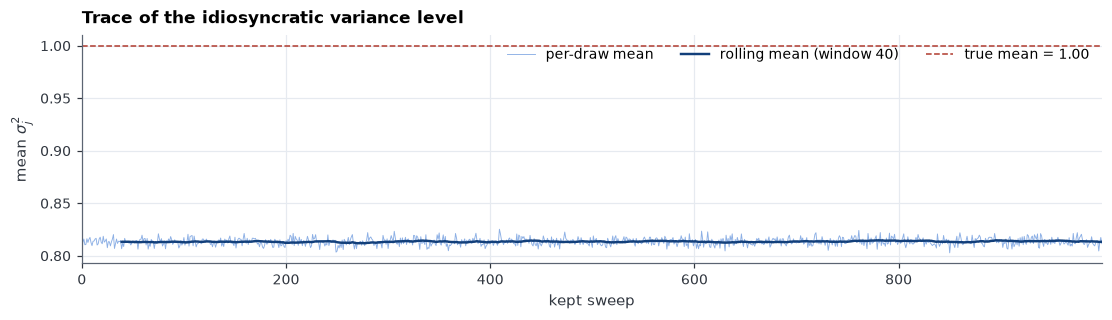

In [12]:
trace = gs.sigma2_samples_.mean(axis=1)
window = max(1, len(trace) // 25)
rolling = np.convolve(trace, np.ones(window) / window, mode="valid")

fig, ax = plt.subplots(figsize=(10, 2.8), constrained_layout=True)
ax.plot(trace, color=C_GS, lw=0.6, alpha=0.55, label="per-draw mean")
ax.plot(np.arange(window - 1, len(trace)), rolling, color="#123f7a",
        lw=1.6, label=f"rolling mean (window {window})")
ax.axhline(float(np.mean(s2_true)), color=C_TRUE, ls="--", lw=1.0,
           label=f"true mean = {float(np.mean(s2_true)):.2f}")
ax.set_xlabel("kept sweep")
ax.set_ylabel(r"mean $\sigma_j^2$")
ax.set_title("Trace of the idiosyncratic variance level", loc="left")
ax.set_xlim(0, len(trace) - 1)
ax.legend(loc="upper right", ncol=3)
plt.show()


## 6. Factor switching: RSP alignment and factor scores (final section)

Apply alignment explicitly only after the fitting, recovery, ESS and
uncertainty diagnostics above. This is the **only** `align_factors()` call
in the notebook. At the $H = 50$ setting used here, RSP's default
assignment backend requires Optax; from the `CSP_BFM` directory install
`python -m pip install -e ".[rsp]"` if needed.

- `gs.align_factors()` aligns every retained draw (varimax plus exact
  sign/permutation against a recursive reference) and updates
  `gs.B_hat_` to their aligned mean. `B_samples_` and ESS remain based on
  the original draws. Each draw's covariance $BB^\top$ is unchanged, but
  the plug-in `gs.Sigma_` can change because it uses the outer product of
  the new mean; `gs.Sigma_mc_` is invariant by construction.
- `gs.H_star_samples_` and `gs.n_factors()` (the $H^*$ rule) are computed
  in the prior's coordinate system and are unchanged: the
  increasing-shrinkage prior orders and spikes the columns, so the factor
  dimension is only meaningful before alignment. The marginal-credible
  variant `n_factors(method="credible")` is invariant to sign flips and
  permutations but not to the varimax rotation; `use_aligned=True` switches
  its input draws.
- **Scores on demand:** `gs.sample_factors(X, ...)` draws scores
  conditional on each retained loading/noise pair. Pass the original
  uncentered `X`; the fitted centering offset is applied internally. These
  are fresh conditional draws, not the historical intermediate scores from
  the Gibbs sweeps.

Orientation alone does not establish better recovery: the column-dependent
CSP prior is not invariant to general rotations or permutations —
alignment selects a representation for display and comparison. The
before/after audit that follows checks that the raw chain is untouched.


In [13]:
# ---------------------------------------------------------------------------
# Pre-RSP snapshot. B_samples_ is the large array: hash its bytes through
# the buffer protocol instead of copying it. Sigma_mc_ is cached by the
# estimator, so compare against a copy, never against the cache itself.
# ---------------------------------------------------------------------------
def array_digest(a):
    if not a.flags.c_contiguous:
        raise ValueError("array_digest expects a C-contiguous array")
    return hashlib.blake2b(memoryview(a).cast("B"), digest_size=16).hexdigest()


if hasattr(gs, "rsp_result_"):
    raise RuntimeError(
        "RSP has already been applied to this estimator; rerun the fit "
        "cell to start a fresh chain before running this section again."
    )

B_shape_before = gs.B_samples_.shape
B_dtype_before = gs.B_samples_.dtype
B_digest_before = array_digest(gs.B_samples_)
H_star_before = gs.H_star_samples_.copy()
sigma2_hat_before = gs.sigma2_hat_.copy()
Sigma_mc_before = gs.Sigma_mc_.copy()
n_factors_before = gs.n_factors()
n_credible_before = n_credible   # raw credible count computed in Section 3

B_raw_mean = gs.B_samples_.mean(axis=0)
check_features = np.unique(np.linspace(
    0, B_raw_mean.shape[0] - 1, min(32, B_raw_mean.shape[0]), dtype=int,
))
noise_block = np.diag(gs.sigma2_hat_[check_features])
gs_plugin_raw_block = (B_raw_mean[check_features]
                       @ B_raw_mean[check_features].T + noise_block)

# This is the only RSP call in the notebook; every diagnostic above is pre-RSP.
gs.align_factors()

result = gs.rsp_result_
print(f"RSP: status={int(result.status_code)}, "
      f"stop={result.diagnostics['stop_reason']}, "
      f"iterations={int(result.n_iter)}, "
      f"final loss={float(result.loss_final):.6g}")
print("diagnostics:", result.diagnostics)

np.testing.assert_allclose(gs.B_hat_, gs.B_aligned_.mean(axis=0),
                           rtol=2e-5, atol=2e-6)
assert gs.B_samples_.shape == B_shape_before
assert gs.B_samples_.dtype == B_dtype_before
assert array_digest(gs.B_samples_) == B_digest_before
np.testing.assert_array_equal(gs.H_star_samples_, H_star_before)
np.testing.assert_array_equal(gs.sigma2_hat_, sigma2_hat_before)
np.testing.assert_array_equal(gs.Sigma_mc_, Sigma_mc_before)
assert gs.n_factors() == n_factors_before
print(f"raw B_samples_ unchanged (blake2b {B_digest_before[:12]}...), "
      f"H* chain unchanged, sigma2_hat_ unchanged, Sigma_mc_ unchanged; "
      f"n_factors() = {gs.n_factors()} before and after alignment.")


RSP: status=1, stop=converged_threshold, iterations=29, final loss=4.49673e+06
diagnostics: {'initial_reference_near_zero': False, 'sp_path': 'elim', 'assignment_backend': 'auto', 'rotated': True, 'precision': 'float32', 'stop_reason': 'converged_threshold', 'nonfinite_fields': ()}


raw B_samples_ unchanged (blake2b 0edb0c24a045...), H* chain unchanged, sigma2_hat_ unchanged, Sigma_mc_ unchanged; n_factors() = 4 before and after alignment.


### 6a. CSP prior, factor counts and all-$H$ column norms before / after alignment

This is the CSP counterpart of the reference notebook's before/after
count-and-norm audit. It asserts the actual estimator settings
(hyperparameters, truncation, seed, shapes), lists the $H^*$ and
credible counts, and prints all $H = 50$ column norms in the raw and
aligned coordinate systems.

The norm columns are deliberately different:

- `drawL2` is the posterior mean of the **per-draw** column L2 norm,
  $\frac1S\sum_s\|B_{\cdot h}^{(s)}\|_2$ — the quantity plotted in
  Section 3;
- `meanL2` is the L2 norm of the **posterior mean** column,
  $\|\frac1S\sum_s B_{\cdot h}^{(s)}\|_2$;
- `maxabs` is the L$\infty$ norm of the posterior mean column,
  $\max_j|\frac1S\sum_s B_{jh}^{(s)}|$.

The max-abs columns are descriptive only. CSP factor selection uses the
$H^*$ posterior (with the credible rule as an auxiliary check); no
max-abs threshold is applied here.


In [14]:
assert DATA_SEED == 1 and SAMPLER_SEED == 2025
assert H == 50 and N_ITER == 20000 and BURN_IN == 10000 and THIN == 10
assert (ALPHA, A_THETA, B_THETA, THETA_INF, A_SIGMA, B_SIGMA) == (
    5.0, 2.0, 2.0, 0.05, 1.0, 0.3)

expected_settings = {
    "H": H,
    "alpha": ALPHA,
    "a_theta": A_THETA,
    "b_theta": B_THETA,
    "theta_inf": THETA_INF,
    "a_sigma": A_SIGMA,
    "b_sigma": B_SIGMA,
    "n_iter": N_ITER,
    "burn_in": BURN_IN,
    "thin": THIN,
}
for name, value in expected_settings.items():
    actual = getattr(gs, name)
    assert actual == value, f"{name}: {actual!r} != {value!r}"
assert gs.seed == SAMPLER_SEED and gs.seed_ == SAMPLER_SEED
assert gs.center is True
assert gs.n_samples_ == N and gs.n_features_in_ == P
assert gs.B_samples_.shape == (S, P, H)
assert gs.sigma2_samples_.shape == (S, P)
assert gs.H_star_samples_.shape == (S,)
assert gs.B_aligned_.shape == (S, P, H)

pi_H_prior = 1.0 - (gs.alpha / (1.0 + gs.alpha)) ** gs.H
h_star_prior = gs.alpha * (1.0 - (gs.alpha / (1.0 + gs.alpha)) ** (gs.H - 1))
print("CSP settings and prior checks")
print(f"  H={gs.H}, alpha={gs.alpha:g}, a_theta={gs.a_theta:g}, "
      f"b_theta={gs.b_theta:g}, theta_inf={gs.theta_inf:g}, "
      f"a_sigma={gs.a_sigma:g}, b_sigma={gs.b_sigma:g}")
print(f"  sweeps={gs.n_iter}, burn-in={gs.burn_in}, thin={gs.thin}, "
      f"kept={S}; seeds: data={DATA_SEED}, sampler={gs.seed_}")
print(f"  prior E[pi_H] = {pi_H_prior:.6f}; "
      f"prior E[H*] under truncation = {h_star_prior:.4f}")

n_hstar_after = gs.n_factors()
assert n_hstar_after == n_factors_before
n_credible_aligned = gs.n_factors(method="credible", use_aligned=True)
print("\nFactor counts (H* is meaningful only in the raw prior coordinates)")
print(f"{'Count rule':<36} {'Before RSP':>12} {'After RSP':>12}")
print(f"{'H* median (raw, default)':<36} {n_factors_before:>12d} "
      f"{n_hstar_after:>12d}")
print(f"{'credible, raw draws':<36} {n_credible_before:>12d} "
      f"{'unchanged':>12}")
print(f"{'credible, aligned draws':<36} {'n/a':>12} "
      f"{n_credible_aligned:>12d}")
print("Raw B_samples_ is byte-identical after alignment (digest in "
      "Section 6), so the raw credible count cannot change; the aligned "
      "credible count uses the varimax-rotated draws.")

B_raw_mean = gs.B_samples_.mean(axis=0)
B_aligned_mean = gs.B_aligned_.mean(axis=0)
np.testing.assert_allclose(B_aligned_mean, gs.B_hat_, rtol=2e-5, atol=2e-6)

raw_draw_l2 = np.linalg.norm(gs.B_samples_, axis=1).mean(axis=0)
aligned_draw_l2 = np.linalg.norm(gs.B_aligned_, axis=1).mean(axis=0)
raw_mean_l2 = np.linalg.norm(B_raw_mean, axis=0)
aligned_mean_l2 = np.linalg.norm(B_aligned_mean, axis=0)
raw_mean_maxabs = np.max(np.abs(B_raw_mean), axis=0)
aligned_mean_maxabs = np.max(np.abs(B_aligned_mean), axis=0)

norm_columns = {
    "raw drawL2": raw_draw_l2,
    "aln drawL2": aligned_draw_l2,
    "raw meanL2": raw_mean_l2,
    "aln meanL2": aligned_mean_l2,
    "raw maxabs": raw_mean_maxabs,
    "aln maxabs": aligned_mean_maxabs,
}
for label, values in norm_columns.items():
    assert values.shape == (H,), f"{label}: {values.shape}"

print(f"\nAll-H column norms: H={H}, true r={K0}, H-r={H - K0} excess "
      f"columns, H* median={n_hstar_after}, inactive columns="
      f"{H - n_hstar_after}")
print(f"spike floor sqrt(p*theta_inf) = {np.sqrt(P * gs.theta_inf):.4f}")
print("drawL2 = (1/S) sum_s ||B_s[:, h]||_2; "
      "meanL2 = ||(1/S) sum_s B_s[:, h]||_2;")
print("maxabs = max_j |(1/S) sum_s B_s[j, h]| "
      "(descriptive only, no threshold).")
print(f"{'h':>3}" + "".join(f"{label:>13}" for label in norm_columns))
for h in range(H):
    print(f"{h + 1:3d}" + "".join(
        f"{values[h]:13.4f}" for values in norm_columns.values()))


CSP settings and prior checks
  H=50, alpha=5, a_theta=2, b_theta=2, theta_inf=0.05, a_sigma=1, b_sigma=0.3
  sweeps=20000, burn-in=10000, thin=10, kept=1000; seeds: data=1, sampler=2025
  prior E[pi_H] = 0.999890; prior E[H*] under truncation = 4.9993



Factor counts (H* is meaningful only in the raw prior coordinates)
Count rule                             Before RSP    After RSP
H* median (raw, default)                        4            4
credible, raw draws                             4    unchanged
credible, aligned draws                       n/a            4
Raw B_samples_ is byte-identical after alignment (digest in Section 6), so the raw credible count cannot change; the aligned credible count uses the varimax-rotated draws.



All-H column norms: H=50, true r=5, H-r=45 excess columns, H* median=4, inactive columns=46
spike floor sqrt(p*theta_inf) = 9.8894
drawL2 = (1/S) sum_s ||B_s[:, h]||_2; meanL2 = ||(1/S) sum_s B_s[:, h]||_2;
maxabs = max_j |(1/S) sum_s B_s[j, h]| (descriptive only, no threshold).
  h   raw drawL2   aln drawL2   raw meanL2   aln meanL2   raw maxabs   aln maxabs
  1      24.3927      22.3266      22.0548      20.1476       1.2855       1.3667
  2      22.3969      17.7829      20.4358      14.2710       1.1366       1.0231
  3      22.9880      23.7226      20.3985      22.3085       0.9326       1.4648
  4      17.4430      22.0088      14.5747      19.9340       0.6975       1.3847
  5       9.6877       9.7535       0.9062       2.1734       0.0606       0.2131
  6       9.6830       9.7484       1.2254       2.3082       0.0828       0.3775
  7       9.6945       9.7130       0.9464       2.0012       0.0735       0.2139
  8       9.6712       9.7653       0.6082       2.3841       0

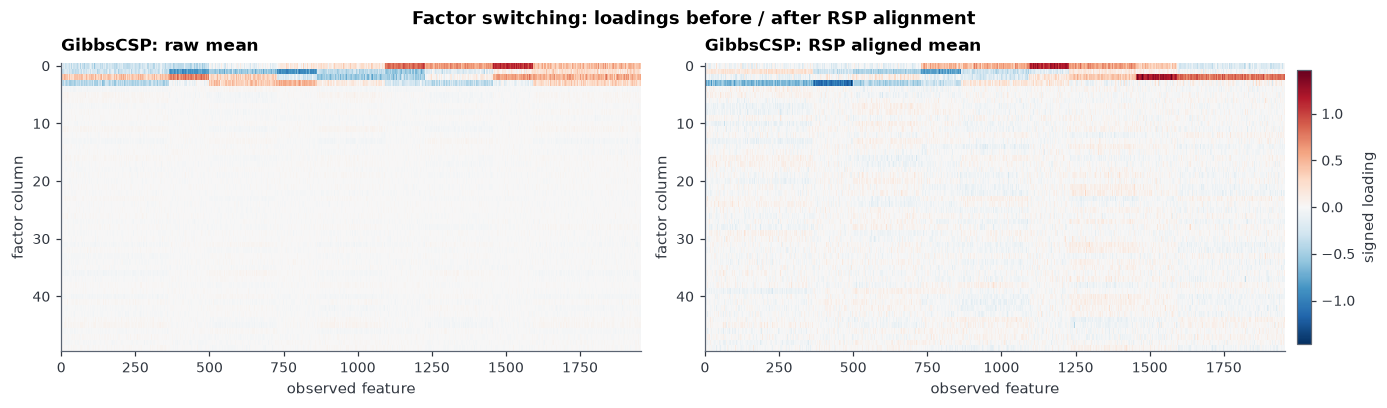

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6), constrained_layout=True)
limit = max(float(np.max(np.abs(B_raw_mean))),
            float(np.max(np.abs(gs.B_hat_))), 1e-8)
for ax, (label, loadings) in zip(
    axes, (("raw mean", B_raw_mean), ("RSP aligned mean", gs.B_hat_))
):
    im = ax.imshow(loadings.T, aspect="auto", interpolation="nearest",
                   cmap="RdBu_r", vmin=-limit, vmax=limit)
    ax.set_title(f"GibbsCSP: {label}", loc="left")
    ax.set_xlabel("observed feature")
    ax.set_ylabel("factor column")
    ax.grid(False)
cb = fig.colorbar(im, ax=axes, pad=0.01, shrink=0.95)
cb.set_label("signed loading")
fig.suptitle("Factor switching: loadings before / after RSP alignment",
             fontweight="bold")
plt.show()


In [16]:
scores = gs.sample_factors(
    X, return_eta=True, return_eta_aligned=True,
    seed=SAMPLER_SEED, batch_size=32,
)
eta_sample = scores["eta_sample"]
eta_sample_aligned = scores["eta_sample_aligned"]
assert eta_sample.shape == (S, H, N)
assert eta_sample_aligned.shape == (S, H, N)
print("eta_sample / eta_sample_aligned:",
      eta_sample.shape, eta_sample_aligned.shape, "(S, H, n)")


def relative_difference(actual, expected):
    scale = max(float(np.linalg.norm(expected)), np.finfo(float).tiny)
    return float(np.linalg.norm(actual - expected)) / scale


# Compare paired scores for ONE draw and a small set of features.
s = S // 2
B_raw_selected = gs.B_samples_[s, check_features]
B_aligned_selected = gs.B_aligned_[s, check_features]
common_raw = B_raw_selected @ eta_sample[s]
common_aligned = B_aligned_selected @ eta_sample_aligned[s]
np.testing.assert_allclose(common_aligned, common_raw, rtol=1e-4, atol=1e-4)
cov_raw = B_raw_selected @ B_raw_selected.T
cov_aligned = B_aligned_selected @ B_aligned_selected.T
np.testing.assert_allclose(cov_aligned, cov_raw, rtol=1e-4, atol=1e-4)
print(f"draw {s}: relative B@eta difference = "
      f"{relative_difference(common_aligned, common_raw):.3e}; "
      f"relative BB.T submatrix difference = "
      f"{relative_difference(cov_aligned, cov_raw):.3e}")

gs_plugin_aligned_block = (gs.B_hat_[check_features]
                           @ gs.B_hat_[check_features].T + noise_block)
print("plug-in Sigma_ relative change on selected features:",
      f"{relative_difference(gs_plugin_aligned_block, gs_plugin_raw_block):.3e}")
# Sigma_ can change even though each aligned draw preserves BB.T.


eta_sample / eta_sample_aligned: (1000, 50, 100) (1000, 50, 100) (S, H, n)
draw 500: relative B@eta difference = 3.114e-07; relative BB.T submatrix difference = 2.402e-07
plug-in Sigma_ relative change on selected features: 1.153e-01


## Summary

- **Dimension and the $H = 50$ truncation.** The CSP prior selects the
  factor dimension through the sampled $H^*$ chain (Section 3).
  `n_factors()` reports its posterior median; the entry-wise credible rule
  is auxiliary. With $H = 50$ and $r = 5$, there are $H-r = 45$ excess
  columns before any block is absorbed. If the $H^*$ posterior selects
  four factors (the current analysis), there are 46 inactive columns
  ($50 - 4 = 46$): those 45 plus one true block absorbed by the spike;
  the 50th column is one of those spiked columns by construction. The
  positive spike variance
  $\theta_\infty = 0.05$ is what gives the spiked columns aggregate
  slack: every spiked column has marginal variance $\theta_\infty$ at
  every entry, so the inactive columns collectively carry variance that
  can absorb a weak block without an active factor. This is distinct from
  the **computational** cost of over-truncation: the 45 excess columns
  enlarge each sweep and the stored loading array even when they are
  spiked, while the aggregate slack is a **statistical** consequence of
  $\theta_\infty > 0$.
- **Recovery (pre-RSP).** Section 4 constructs the plug-in explicitly from
  raw draw means and reports absolute and relative Frobenius errors,
  principal-angle cosines and truth/MC/plug-in covariance heatmaps.
  Section 4c uses the cheap diagonal and selected-pair posterior moments;
  the full $p \times p$ variance matrix is budget-guarded and is not
  needed here. Section 5 reports bulk ESS when ArviZ is installed; spike
  entries mix slowly by design, while signal entries are the relevant
  ones for the ~400 rule.
- **RSP audit.** Section 6 calls `align_factors()` once. The raw
  `B_samples_` array is checked by a full byte digest (no copy), and the
  $H^*$ chain, `sigma2_hat_`, `Sigma_mc_` and the default `n_factors()`
  count are checked against pre-alignment snapshots; `Sigma_mc_` is
  compared against a copy, not the estimator cache. Section 6a checks the
  CSP hyperparameters, truncation and seed, lists the $H^*$ and credible
  counts, and prints all $H = 50$ raw/aligned norm columns. The max-abs
  columns are descriptive; no max-abs threshold is used.
- **Scores and plug-in.** The aligned factor scores satisfy
  $B_{\text{aligned}}\,\eta_{\text{aligned}} = B\,\eta$ up to numerical
  precision for the selected draw and feature block, and each draw's
  $BB^\top$ covariance is preserved. The plug-in `gs.Sigma_` can still
  change because it uses the mean of the aligned draws.
- **Verification.** The numerical results in this notebook — posterior
  summaries, errors, ESS values, RSP diagnostics and timings — are
  produced by the run; no fitted value or timing is hard-coded in this
  summary. Rerun the notebook from the top after choosing `MODE` in the
  first cell.
